# Basics: your first experiments

Tinto bundles a graph, a coloring config, a starter, a scheduler and a solver into an `Experiment` object that sweeps a parameter, runs Monte-Carlo trials, aggregates statistics, plots and exports. This notebook walks through four progressively richer examples so you become comfortable with that high-level API.

If you have not yet, skim the README's Quickstart first — it covers the low-level building blocks this tutorial stands on.

**In this notebook:**

1. **A first double campaign** — sweep the length of a line graph, for two different initial colorings.
2. **Comparing with theory** — overlay closed-form formulas on the simulation.
3. **Schedulers: Bernoulli vs Local** — explore a scheduler parameter.
4. **Saving results** — export a campaign to CSV.

## A first double campaign

We measure the *convergence time* — the number of steps before the coloring stabilizes — as a function of the length `n` of a line graph, starting from two different initial colorings: *uniform* (all nodes share the same color) and *random*.

First, the imports:

In [1]:
from functools import partial

import numpy as np
from matplotlib import pyplot as plt

from tinto import Experiment, Iterator
from tinto import configs, graphs, schedulers, solvers, starters

A few setup decisions: we use the default config builder (clash guard), and define a helper that turns an `(n, random)` pair into a properly-typed starter.

In [2]:
# Default config builder: clash guard behind the scenes.
Config = configs.make()

# Two config generators: uniform and random coloring.
starter_uniform = starters.from_graph(Config, color=0)
starter_random = starters.from_graph(Config)


def line_starter(n, random):
    builder = starter_random if random else starter_uniform
    return builder(graphs.line(n=n))

We define two campaigns that share the same sweep over `n` but differ in their starter flavour, sum them into one `Experiment` and run:

In [3]:
base_iter = {"parameter": "starter", "values": np.arange(5, 101, 5), "name": "$n$"}
lines = Iterator(process=partial(line_starter, random=True), **base_iter)
mono_lines = Iterator(process=partial(line_starter, random=False), **base_iter)

base = {
    "scheduler": schedulers.shuffled(),
    "solver": solvers.make(),
    "n_trials": 100000,
}
exp = Experiment("Uniform", iterator=mono_lines, **base) + Experiment(
    "Random", iterator=lines, **base
)

_ = exp.run()

Uniform:   0%|          | 0/20 [00:00<?, ?it/s]

Random:   0%|          | 0/20 [00:00<?, ?it/s]

Let us see the result:

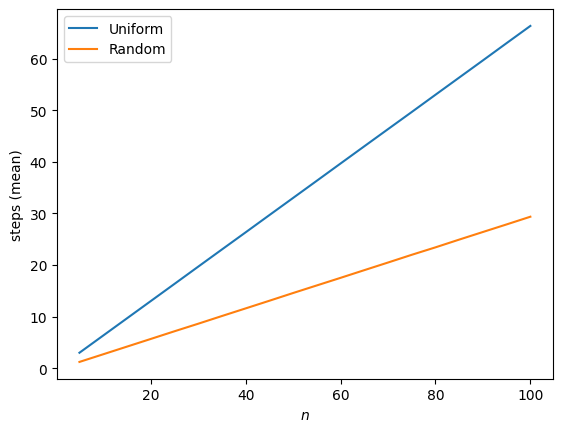

In [4]:
exp.plot()
plt.show()

Both settings scale linearly with `n`, with the random start taking slightly longer to converge.

*See also: the [Experiments reference](../reference/experiments.md) and the [Starters reference](../reference/starters.md).*

## Comparing with theory

Closed-form expressions are known for these two setups on the line graph under shuffled scheduling (<!-- TODO: add citation / reference -->):

- uniform start — mean: $\frac{2n-1}{3}$, variance: $\frac{2n+2}{45}$
- random start — mean: $\frac{8n-7}{27}$

Let us overlay them on the simulations:

In [5]:
def mono_mean(n):
    return (2 * n - 1) / 3


def mono_var(n):
    return (2 * n + 2) / 45


def random_mean(n):
    return (8 * n - 7) / 27

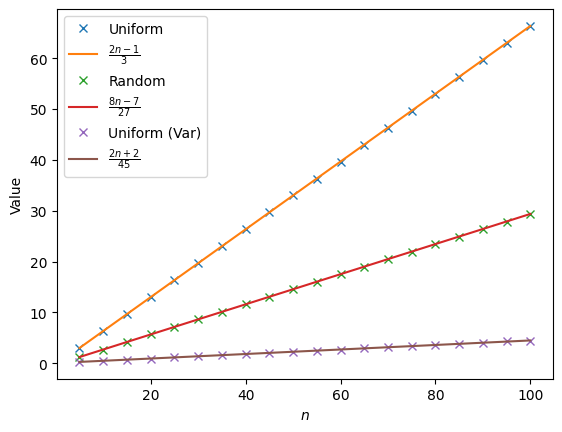

In [6]:
x = exp.series()["Uniform"][0]

exp.plot(campaign="Uniform", marker="x", linestyle="")
plt.plot(x, [mono_mean(xx) for xx in x], label=r"$\frac{2n-1}{3}$")

exp.plot(campaign="Random", marker="x", linestyle="")
plt.plot(x, [random_mean(xx) for xx in x], label=r"$\frac{8n-7}{27}$")

exp.plot(
    campaign="Uniform", stat="var", marker="x", linestyle="", label="Uniform (Var)"
)
plt.plot(x, [mono_var(xx) for xx in x], label=r"$\frac{2n+2}{45}$")

plt.ylabel("Value")
plt.legend()
plt.show()

The simulated markers land on the theoretical curves — a good sanity check that the Monte-Carlo estimator is unbiased.

*See also: `Experiment.series` and `Experiment.plot` in the [Experiments reference](../reference/experiments.md).*

## Schedulers: Bernoulli vs Local

So far we have used `schedulers.shuffled()` (a.k.a. *Central*), which picks nodes along a random permutation each step. Two other schedulers are driven by a probability $p$:

- **Bernoulli** (a.k.a. *Distributed*): each enabled node independently fires with probability $p$. Trivial to implement in a distributed setting, but can produce destructive concurrent updates.
- **Independent** (a.k.a. *Local*): a locally-computed maximal independent set of enabled nodes fires. More careful, but also requires more coordination.

Let us sweep $p$ and compare both in terms of steps and activations:

In [7]:
def make_scheduler(p, independent):
    return schedulers.independent(p) if independent else schedulers.bernoulli(p)


Config = configs.make()
solver = solvers.make()
starter = starters.from_graph(Config, color=0)(graphs.line())  # default n=100

In [8]:
base_iter = {
    "parameter": "scheduler",
    "values": [p / 100 for p in range(1, 100)],
    "name": "$p$",
}
inde = Iterator(process=partial(make_scheduler, independent=True), **base_iter)
bernou = Iterator(process=partial(make_scheduler, independent=False), **base_iter)

base = {"starter": starter, "solver": solver, "n_trials": 100000}
exp = Experiment("Local", iterator=inde, **base) + Experiment(
    "Distributed", iterator=bernou, **base
)

_ = exp.run()

Local:   0%|          | 0/99 [00:00<?, ?it/s]

Distributed:   0%|          | 0/99 [00:00<?, ?it/s]

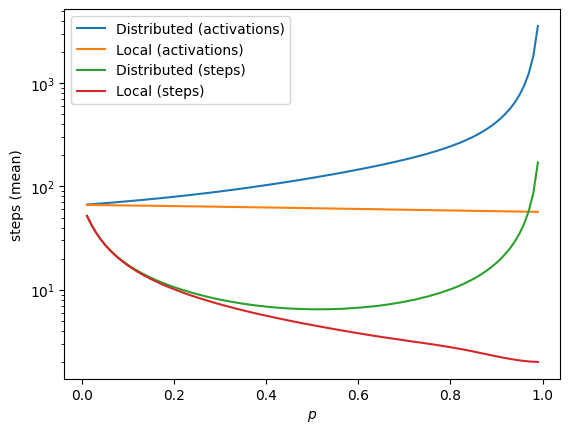

In [9]:
exp.plot(
    campaign="Distributed",
    metric="activations",
    label="Distributed (activations)",
    scale="logy",
)
exp.plot(
    campaign="Local", metric="activations", label="Local (activations)", scale="logy"
)
exp.plot(
    campaign="Distributed", metric="steps", label="Distributed (steps)", scale="logy"
)
exp.plot(campaign="Local", metric="steps", label="Local (steps)", scale="logy")
plt.show()

Both schedulers need fewer steps as $p$ grows, but Distributed pays for concurrency with many more activations (and steps, indeed) when $p$ is large. Apparently, there is a sweet spot for $p$ with Distributed.

*See also: the [Schedulers reference](../reference/schedulers.md).*

## Saving results

Every `Experiment` can be flattened to a CSV — one row per data point, columns for the campaign, each axis and each metric/stat pair.

In [10]:
from pathlib import Path

path = Path("schedulers.csv")
exp.to_csv(path)
with path.open() as f:
    for _, line in zip(range(6), f):
        print(line.rstrip())
path.unlink()  # tidy up the tutorial artifact

campaign,scheduler,steps_mean,steps_var,steps_m3,activations_mean,activations_var,activations_m3
Local,0.01,51.90943,11.383807075099867,-1.124132840661332,66.24772,4.480794801600496,0.17671114834956825
Local,0.02,42.25748,11.227044049599954,1.9122522130201105,66.1768,4.4584617600003185,0.1916854256996885
Local,0.03,35.53641,9.618834311900173,1.973448959790403,66.10086,4.409127260400965,0.24694025109056383
Local,0.04,30.63495,8.269828497500043,1.6912597905247821,66.0184,4.449561440000252,0.25925797887612134
Local,0.05,26.93518,7.00265836760002,1.7329692959756358,65.91679,4.372006095898541,0.154950019903481


From there pandas, a spreadsheet or any downstream tool can pick up. This closes the basics loop: build → run → plot → save.

*See also: `Experiment.to_csv` in the [Experiments reference](../reference/experiments.md).*